# 02. 서열–기능 텍스트 대조 정렬(toy CLIP) — 보지 못한 단백질의 설명을 찾을 수 있는가?

**등급**: 🟢 Mac 로컬 (MPS/CPU) · Colab T4에서도 실행 확인(약 25분) · **예상 시간**: 약 9분 (임베딩이 캐시에 있으면 그보다 짧고, 첫 실행은 ESM-2 35M 임베딩이 추가된다) · **다운로드**: UniProt REST(사람 reviewed 단백질 7,418개, 약 3.4 MB gz), all-MiniLM-L6-v2 약 91 MB; ESM-2 35M은 모듈 02에서 받아 둔 캐시를 쓴다(없으면 약 140 MB를 받는다)

**질문**: 단백질 서열 임베딩과 기능 설명(텍스트) 임베딩을 **대조학습(InfoNCE)**으로 같은 공간에 정렬하면, 학습에 없던 단백질에 대해 서열로 설명을, 설명으로 서열을 찾을 수 있는가? 이 성능은 **homolog가 train에 있을 때** 얼마나 부풀려지는가? 정렬을 학습하지 않는 단순 baseline과 비교하면 어떤가?

**설계 (결과를 보기 전에 정한 것)**
- 데이터: UniProtKB/Swiss-Prot(reviewed) **사람** 단백질 중 길이 80–400, `Function [CC]`와 Pfam이 있는 7,418개에서 **서열이 글자까지 같은 21개를 뺀**(첫 행만 남김) 단백질(릴리스 2026_04). 텍스트 = 정리한 `Function` 설명.
- 인코더(동결): 서열 = ESM-2 35M 마지막 층 평균 풀링(480차원), 텍스트 = all-MiniLM-L6-v2 평균 풀링 + L2 정규화(384차원). **학습하는 것은 양쪽 2층 MLP head(은닉 512 → 256차원, L2 정규화)와 온도뿐**이다.
- 학습: 대칭 InfoNCE, 배치 256, AdamW(lr 1e-3, wd 1e-2), 40 에폭, 초기 온도 0.07(학습 가능). 이 값들은 **미리 고정**했고 test 성능으로 고르지 않았다(민감도는 §7에서 따로 본다).
- 분할: 5-fold **random** vs 5-fold **Pfam 가족 묶음**(Pfam 도메인을 하나라도 공유하는 단백질은 같은 그룹이고 같은 폴드에 들어간다). 평가는 폴드의 test 전체(≈1,479개)를 후보 갤러리로 쓰는 검색이며, seq→text와 text→seq의 Recall@1/5/10과 중앙 순위(갤러리 대비 비율)를 본다.
- baseline: (i) 우연, (ii) **최근접 전이**(train 중 ESM 코사인이 가장 가까운 단백질의 텍스트를 질의로 사용; 학습 없음), (iii) **선형 사상**(ridge: ESM → 텍스트 임베딩), (iv) **서열 인코더 대조**(아미노산·이펩타이드 조성 420차원으로 같은 정렬 학습). 파이프라인 점검용 대조로 **짝을 섞어서** 학습한다(우연 수준이어야 한다).
- 주 비교(사전 지정): Pfam 묶음 분할에서 **CLIP head vs 최근접 전이**의 seq→text Recall@1, 그리고 random에서 Pfam 묶음으로 갈 때의 하락폭. 구간은 Pfam 그룹 단위 부트스트랩(조건부 구간)이다.

> 텍스트는 UniProt 큐레이터가 쓴 것이며, 상당수가 서열 유사성에 근거한 주석이다(따라서 homolog끼리 문장이 거의 같다). 이것이 아래 결과를 이해하는 핵심 단서다.

In [1]:
import gzip
import hashlib
import importlib.metadata as md
import json
import os
import re
import time
import urllib.parse
import urllib.request
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from Bio import Align
from Bio.Align import substitution_matrices
from scipy import sparse
from scipy.sparse.csgraph import connected_components
from sklearn.model_selection import KFold

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})


def find_root():
    p = Path.cwd().resolve()
    for q in [p, *p.parents]:
        if (q / "SETUP.md").exists():
            return q
    return None


ROOT = find_root()
CACHE = (ROOT / ".cache") if ROOT is not None else Path("cache")
os.environ.setdefault("HF_HOME", str(CACHE / "hf"))
UP = CACHE / "uniprot"
UP.mkdir(parents=True, exist_ok=True)

import torch
import torch.nn as nn
import torch.nn.functional as F
from huggingface_hub import snapshot_download
from transformers import AutoModel, AutoTokenizer, EsmModel
from transformers.utils import logging as hf_logging

hf_logging.set_verbosity_error()
hf_logging.disable_progress_bar()
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
SEED = 0
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(4)
print("device:", DEVICE, "| cache:", CACHE)
print({k: md.version(k) for k in ["numpy", "pandas", "scikit-learn", "torch", "transformers", "biopython"]})

W1110 12:38:57.911000 882 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


device: mps | cache: <repo>/.cache
{'numpy': '2.5.4', 'pandas': '3.1.1', 'scikit-learn': '1.9.1', 'torch': '2.15.0', 'transformers': '5.22.1', 'biopython': '1.88'}


## 1. 데이터: UniProt에서 내려받고 정리하기
- 질의: `reviewed:true AND length:[80 TO 400] AND organism_id:9606 AND cc_function:* AND xref:pfam-*`. REST `search` 엔드포인트를 500개씩 커서로 넘기며 받는다. (`stream` 엔드포인트는 이 환경에서 502를 돌려주었다.) UniProt 내용은 릴리스마다 바뀌므로 **내려받은 릴리스와 파일 해시를 기록**한다. 이 저장소의 결과는 릴리스 2026_04, sha256 `e3acc2dbebb9…`로 얻었다. 데이터는 CC BY 4.0이다.
- 텍스트 정리: 앞의 `FUNCTION:` 제거, `{ECO:…}` 근거 코드·`(PubMed:…)` 인용·`(By similarity)` 표기 제거, 공백 정리. `Similarity` 주석 필드는 애초에 받지 않았다. "Belongs to the … family"가 서열 유사성의 요약이므로 가족 이름을 직접 알려 주기 때문이다. 다만 `Function` 본문에도 가족명이 나올 수 있다.

In [2]:
TSV = UP / "human_reviewed_len80_400.tsv.gz"
QUERY = "(reviewed:true) AND (length:[80 TO 400]) AND (organism_id:9606) AND (cc_function:*) AND (xref:pfam-*)"
FIELDS = "accession,protein_name,gene_primary,length,sequence,cc_function,keyword,xref_pfam,xref_interpro"


def fetch_uniprot(out):
    url = "https://rest.uniprot.org/uniprotkb/search?" + urllib.parse.urlencode({"query": QUERY, "fields": FIELDS, "format": "tsv", "size": 500})
    rows, header, releases = [], None, set()
    while url:
        for attempt in range(5):
            try:
                resp = urllib.request.urlopen(urllib.request.Request(url, headers={"User-Agent": "course-notes/1.0"}), timeout=60)
                break
            except Exception as e:                                   # 일시 오류는 재시도
                print("retry", attempt, e)
                time.sleep(3 * (attempt + 1))
        else:
            raise RuntimeError("UniProt 요청 실패")
        lines = resp.read().decode("utf-8").rstrip("\n").split("\n")
        header = header or lines[0]
        rows += lines[1:]
        releases.add(resp.headers.get("X-UniProt-Release"))
        m = re.search(r'<([^>]+)>;\s*rel="next"', resp.headers.get("Link", ""))
        url = m.group(1) if m else None
    with gzip.open(out, "wt", encoding="utf-8") as f:
        f.write(header + "\n" + "\n".join(rows) + "\n")
    assert len(releases) == 1, f"내려받는 도중 UniProt 릴리스가 바뀌었다: {releases}"       # 페이지마다 릴리스가 같은지 확인
    Path(str(out) + ".release.txt").write_text(f"release={releases.pop()}\n")


if not TSV.exists():
    print("downloading UniProt (약 3.4 MB gz) ...")
    fetch_uniprot(TSV)
rel = Path(str(TSV) + ".release.txt")
TSV_SHA12 = hashlib.sha256(TSV.read_bytes()).hexdigest()[:12]
print("릴리스:", rel.read_text().strip() if rel.exists() else "(기록 없음)", "| sha256", TSV_SHA12, "…",
      "(이 저장소의 결과와 같은 파일)" if TSV_SHA12 == "e3acc2dbebb9" else "(⚠️ 이 저장소의 결과(e3acc2dbebb9…)와 다른 파일: 수치가 달라질 수 있다)")

df = pd.read_csv(TSV, sep="\t")
df.columns = ["acc", "name", "gene", "length", "seq", "func", "kw", "pfam", "interpro"]
N_RAW = len(df)
N_DUP_SEQ = int(df.seq.duplicated().sum())
df = df[~df.seq.duplicated(keep="first")].reset_index(drop=True)        # 글자까지 같은 서열은 첫 행만: 남기면 random 분할에서 train·test에 동시에 들어간다


def clean_function(t):
    t = re.sub(r"^FUNCTION:\s*", "", str(t))
    t = re.sub(r"\{ECO:[^}]*\}", "", t)
    t = re.sub(r"\(PubMed:[^)]*\)", "", t)
    t = re.sub(r"\(By similarity\)", "", t)
    t = re.sub(r"\s+", " ", t).strip()
    return re.sub(r"\s+([.,;])", r"\1", t)


df["text"] = df["func"].map(clean_function)
N = len(df)
print(f"단백질 {N_RAW}개 중 동일 서열 {N_DUP_SEQ}개 제거 → {N}개 | 길이 중앙값 {int(df.length.median())} | 20종 밖 문자 포함 서열 {int(df.seq.str.contains('[^ACDEFGHIKLMNPQRSTVWY]').sum())}개")
print("텍스트 길이(글자) 5/50/95%:", np.percentile(df.text.str.len(), [5, 50, 95]).astype(int).tolist(), "| 자기 유전자 기호가 본문에 있는 비율 %.2f" % np.mean([str(g) in t for g, t in zip(df.gene, df.text)]))
print("예:", df.text.sample(3, random_state=0).str[:150].tolist())

릴리스: release=2026_04 | sha256 e3acc2dbebb9 … (이 저장소의 결과와 같은 파일)
단백질 7418개 중 동일 서열 21개 제거 → 7397개 | 길이 중앙값 266 | 20종 밖 문자 포함 서열 18개


텍스트 길이(글자) 5/50/95%: [18, 335, 1472] | 자기 유전자 기호가 본문에 있는 비율 0.12
예: ['Capable of inducing cell cycle arrest in G1 and G2 phases. Acts as a tumor suppressor. Binds to MDM2 and blocks its nucleocytoplasmic shuttling by seq', 'Component of the large ribosomal subunit. The ribosome is a large ribonucleoprotein complex responsible for the synthesis of proteins in the cell..', 'Binds to actin filaments in muscle and non-muscle cells. Plays a central role, in association with the troponin complex, in the calcium dependent regu']


## 2. 동결 인코더로 임베딩 만들기
- **서열**: ESM-2 35M(`facebook/esm2_t12_35M_UR50D`) 마지막 층, `<cls>`·`<eos>`·패딩을 뺀 평균.
- **텍스트**: all-MiniLM-L6-v2. sentence-transformers 패키지 없이 `transformers`로 재현한다: 토큰 256개까지 자르고, 패딩을 뺀 **평균 풀링** 뒤 **L2 정규화**. 저장소의 `modules.json`·`1_Pooling/config.json`·`sentence_bert_config.json`을 읽어 이 파이프라인과 맞는지 확인한다.
- 계산이 끝나면 `.cache/uniprot/`에 저장한다(같은 데이터 해시이면 재사용).

In [3]:
MINILM = ("sentence-transformers/all-MiniLM-L6-v2", "1110a243fdf4706b3f48f1d95db1a4f5529b4d41")
mini_dir = Path(snapshot_download(MINILM[0], revision=MINILM[1], allow_patterns=["model.safetensors", "*.json", "vocab.txt", "1_Pooling/config.json"]))
mods = json.loads((mini_dir / "modules.json").read_text())
pool_cfg = json.loads((mini_dir / "1_Pooling" / "config.json").read_text())
sb_cfg = json.loads((mini_dir / "sentence_bert_config.json").read_text())
print("modules:", [m["type"].split(".")[-1] for m in mods], "| 풀링:", {k: v for k, v in pool_cfg.items() if v is True or k == "word_embedding_dimension"}, "| max_seq_length:", sb_cfg["max_seq_length"])


ESM = ("facebook/esm2_t12_35M_UR50D", "6fbf070e65b0b7291e7bbcd451118c216cff79d8")
esm_dir = Path(snapshot_download(ESM[0], revision=ESM[1], allow_patterns=["model.safetensors", "*.json", "vocab.txt"]))


@torch.no_grad()
def embed_proteins(seqs, batch=32):
    tok = AutoTokenizer.from_pretrained(esm_dir)
    model = EsmModel.from_pretrained(esm_dir, add_pooling_layer=False).eval().to(DEVICE)
    order = np.argsort([len(s) for s in seqs])
    out = np.zeros((len(seqs), model.config.hidden_size), np.float32)
    for s in range(0, len(seqs), batch):
        ix = order[s:s + batch]
        b = tok([seqs[i] for i in ix], return_tensors="pt", padding=True).to(DEVICE)
        h = model(**b).last_hidden_state
        am = b["attention_mask"].clone()
        am[:, 0] = 0
        am[torch.arange(len(ix)), b["attention_mask"].sum(1) - 1] = 0
        out[ix] = ((h * am[..., None]).sum(1) / am.sum(1, keepdim=True)).cpu().numpy()
        del h, b
        if DEVICE.type == "mps":
            torch.mps.empty_cache()
    return out


@torch.no_grad()
def embed_texts(texts, batch=64):
    tok = AutoTokenizer.from_pretrained(mini_dir)
    model = AutoModel.from_pretrained(mini_dir).eval().to(DEVICE)
    order = np.argsort([len(t) for t in texts])
    out = np.zeros((len(texts), model.config.hidden_size), np.float32)
    ntrunc = 0
    for s in range(0, len(texts), batch):
        ix = order[s:s + batch]
        b = tok([texts[i] for i in ix], return_tensors="pt", padding=True, truncation=True, max_length=sb_cfg["max_seq_length"]).to(DEVICE)
        ntrunc += int((b["attention_mask"].sum(1) >= sb_cfg["max_seq_length"]).sum())
        h = model(**b).last_hidden_state
        am = b["attention_mask"][..., None].float()
        out[ix] = F.normalize((h * am).sum(1) / am.sum(1).clamp(min=1e-9), dim=-1).cpu().numpy()
    return out, ntrunc


# 자체 점검: 혼자 넣은 결과 == 패딩된 배치 안의 결과
probe = df.seq.iloc[:6].tolist()
d_esm = np.abs(embed_proteins(probe) - np.stack([embed_proteins([s])[0] for s in probe])).max()
pt = df.text.iloc[:6].tolist()
d_txt = np.abs(embed_texts(pt)[0] - np.stack([embed_texts([t])[0][0] for t in pt])).max()
print("단독 vs 배치 최대 절대차: ESM %.1e | MiniLM %.1e" % (d_esm, d_txt))

modules: ['Transformer', 'Pooling', 'Normalize'] | 풀링: {'word_embedding_dimension': 384, 'pooling_mode_mean_tokens': True} | max_seq_length: 256


단독 vs 배치 최대 절대차: ESM 4.8e-07 | MiniLM 1.4e-07


In [4]:
EMB = UP / "emb05_esm35_minilm.npz"
key = hashlib.sha256("|".join([TSV_SHA12, "dedup-seq", ESM[1], MINILM[1], "torch" + md.version("torch"), "transformers" + md.version("transformers")]).encode()).hexdigest()[:16]
if EMB.exists() and str(np.load(EMB)["key"]) == key:
    z = np.load(EMB)
    E, T = z["E"], z["T"]
    print("캐시된 임베딩 사용:", E.shape, T.shape)
else:
    t0 = time.time()
    E = embed_proteins(df.seq.tolist())
    t1 = time.time()
    T, ntrunc = embed_texts(df.text.tolist())
    print("ESM-2 35M %.0f초 | MiniLM %.0f초 | MiniLM 256토큰에서 잘린 텍스트 %d개 (%.1f%%)" % (t1 - t0, time.time() - t1, ntrunc, 100 * ntrunc / N))
    np.savez(EMB, E=E, T=T, key=np.array(key))
assert np.isfinite(E).all() and np.isfinite(T).all()

캐시된 임베딩 사용: (7397, 480) (7397, 384)


## 3. 그룹, 분할, 그리고 누출을 숫자로 보기
- **Pfam 그룹**: 단백질을 노드, "Pfam 도메인을 하나 이상 공유"를 간선으로 하는 그래프의 연결 요소. 다도메인 단백질 때문에 가족이 합쳐지지만, 이 데이터에서는 거대 요소 하나로 뭉치지 않았다(아래 크기 분포).
- 폴드는 크기를 맞춘 그룹 폴드(큰 그룹부터 가장 작은 폴드에 배정). random 분할은 같은 크기의 단백질 단위 5-fold.
- **누출 측정 ①** test 단백질(폴드 0에서 무작위로 뽑은 300개)마다 train에서 ESM 코사인(train 통계로 표준화) 상위 30개 후보를 BLOSUM62 국소 정렬(gap −11/−1)해 (i) 점수가 가장 높은 후보의 동일도(정렬 열 대비)·질의 커버리지, (ii) 커버리지 ≥ 0.5인 후보 중 최대 동일도를 본다. (MMseqs2 같은 전용 도구가 아니라 근사다. 후보를 ESM 이웃으로 한정했으므로 먼 상동은 놓칠 수 있다.)
- **누출 측정 ②** test 텍스트마다 train 텍스트 중 가장 비슷한 것과의 MiniLM 코사인(같은 문장이 가족 전체에 복사된 정도).

In [5]:
pf = df["pfam"].fillna("").str.strip(";").str.split(";")
pf_ids = {p: i for i, p in enumerate(sorted({p for x in pf for p in x if p}))}
rows_, cols_ = zip(*[(i, pf_ids[p]) for i, x in enumerate(pf) for p in set(x) if p])
M = sparse.csr_matrix((np.ones(len(rows_)), (rows_, cols_)), shape=(N, len(pf_ids)))
n_groups, GROUP = connected_components((M @ M.T) > 0, directed=False)
gs = np.sort(np.bincount(GROUP))[::-1]
print(f"Pfam 도메인 {len(pf_ids)}종 → 그룹 {n_groups}개 | 가장 큰 그룹 {gs[:5].tolist()} (전체의 {100 * gs[0] / N:.1f}%) | 단백질 1개짜리 그룹 {(gs == 1).sum()}개")

K = 5


def random_folds(seed=0):
    return list(KFold(K, shuffle=True, random_state=seed).split(np.arange(N)))


def group_folds(seed=0):
    rng = np.random.default_rng(seed)
    u, inv = np.unique(GROUP, return_inverse=True)
    sizes = np.bincount(inv)
    order = np.lexsort((rng.random(len(u)), -sizes))
    load, assign = np.zeros(K), np.zeros(len(u), int)
    for g in order:
        f = int(np.argmin(load))
        assign[g] = f
        load[f] += sizes[g]
    fo = assign[inv]
    return [(np.where(fo != f)[0], np.where(fo == f)[0]) for f in range(K)]


FOLDS = {"random": random_folds(), "pfam-group": group_folds()}
for sp, fo in FOLDS.items():
    assert sorted(np.concatenate([te for _, te in fo]).tolist()) == list(range(N))
    shared = sum(len(set(GROUP[tr]) & set(GROUP[te])) for tr, te in fo)
    same_seq = sum(int(df.seq.iloc[te].isin(set(df.seq.iloc[tr])).sum()) for tr, te in fo)
    print(f"{sp:10s} test 크기 {[len(te) for _, te in fo]} | train·test가 공유하는 Pfam 그룹 수 합계 {shared} | 서열이 글자까지 같은 train 단백질이 있는 test 수 {same_seq}")

Pfam 도메인 3078종 → 그룹 2229개 | 가장 큰 그룹 [690, 495, 430, 204, 150] (전체의 9.3%) | 단백질 1개짜리 그룹 1419개
random     test 크기 [1480, 1480, 1479, 1479, 1479] | train·test가 공유하는 Pfam 그룹 수 합계 2049 | 서열이 글자까지 같은 train 단백질이 있는 test 수 0


pfam-group test 크기 [1480, 1480, 1479, 1479, 1479] | train·test가 공유하는 Pfam 그룹 수 합계 0 | 서열이 글자까지 같은 train 단백질이 있는 test 수 0


In [6]:
ALIGNER = Align.PairwiseAligner(mode="local", substitution_matrix=substitution_matrices.load("BLOSUM62"), open_gap_score=-11, extend_gap_score=-1)
ALN_SEQ = [re.sub(r"[^ACDEFGHIKLMNPQRSTVWYBZX]", "X", x) for x in df.seq]      # BLOSUM62에 없는 문자(U 등)는 X로


def nearest_identity(tr, te, n_query=300, topk=30, seed=0):
    """폴드의 test에서 n_query개를 뽑아, train에서 ESM 코사인 상위 topk개 후보를 전부 정렬한다.
    반환 열: [점수가 가장 높은 후보의 동일도, 그 후보의 질의 커버리지, 커버리지 ≥ 0.5인 후보들 중 최대 동일도]."""
    rng = np.random.default_rng(seed)
    q = rng.choice(te, size=min(n_query, len(te)), replace=False)
    mu, sd = E[tr].mean(0), E[tr].std(0) + 1e-6                                  # 후보 검색용 표준화도 train 통계만
    A, B_ = (E[q] - mu) / sd, (E[tr] - mu) / sd
    sims = (A / np.linalg.norm(A, axis=1, keepdims=True)) @ (B_ / np.linalg.norm(B_, axis=1, keepdims=True)).T
    out = []
    for qi, row in zip(q, sims):
        stats = []
        for c in tr[np.argsort(-row)[:topk]]:
            aln = ALIGNER.align(ALN_SEQ[qi], ALN_SEQ[c])[0]
            stats.append((aln.score, aln.counts().identities / aln.shape[1], sum(e - s for s, e in aln.aligned[0]) / len(ALN_SEQ[qi])))
        stats = np.array(stats)
        best = stats[np.argmax(stats[:, 0])]
        ok = stats[stats[:, 2] >= 0.5]
        out.append((best[1], best[2], ok[:, 1].max() if len(ok) else 0.0))
    return np.array(out)


t0 = time.time()
ID = {sp: nearest_identity(*FOLDS[sp][0]) for sp in FOLDS}
print("정렬 기반 근사: %.0f초" % (time.time() - t0))
rows = []
for sp, a in ID.items():
    rows.append(dict(분할=sp, **{"최근접 동일도 중앙값": np.median(a[:, 0]), "동일도≥30%": np.mean(a[:, 0] >= 0.3), "동일도≥50%": np.mean(a[:, 0] >= 0.5), "동일도≥90%": np.mean(a[:, 0] >= 0.9),
                        "질의 커버리지 중앙값": np.median(a[:, 1]), "최고점수 후보가 동일도≥30%·커버리지≥50%": np.mean((a[:, 0] >= 0.3) & (a[:, 1] >= 0.5)),
                        "상위30 중 커버리지≥50% 후보의 최대 동일도≥30%": np.mean(a[:, 2] >= 0.3)}))
print(pd.DataFrame(rows).round(2).to_string(index=False))

정렬 기반 근사: 24초
        분할  최근접 동일도 중앙값  동일도≥30%  동일도≥50%  동일도≥90%  질의 커버리지 중앙값  최고점수 후보가 동일도≥30%·커버리지≥50%  상위30 중 커버리지≥50% 후보의 최대 동일도≥30%
    random         0.37     0.68     0.36     0.05         0.79                       0.54                            0.57
pfam-group         0.29     0.40     0.04     0.00         0.32                       0.05                            0.08


In [7]:
ND = {}
for sp, fo in FOLDS.items():
    nd = np.zeros(N)
    for tr, te in fo:
        nd[te] = (T[te] @ T[tr].T).max(1)
    ND[sp] = nd
print(pd.DataFrame({sp: {"텍스트 최근접 코사인 중앙값": np.median(v), "≥0.9인 test 텍스트 비율": np.mean(v >= 0.9), "≥0.8": np.mean(v >= 0.8)} for sp, v in ND.items()}).round(2).to_string())
for sp, fo in FOLDS.items():
    twin = np.mean([df.text.iloc[te].duplicated(keep=False).mean() for _, te in fo])
    seen = np.mean([df.text.iloc[te].isin(set(df.text.iloc[tr])).mean() for tr, te in fo])
    print(f"{sp:10s} 같은 갤러리 안에 글자까지 같은 텍스트를 가진 다른 질의가 있는 test 비율 {twin:.2f} | test 텍스트가 train 텍스트와 글자까지 같은 비율 {seen:.2f}")
print("\n가장 흔한 텍스트(앞 80자):")
print(df.text.str[:80].value_counts().head(4).to_string())

                   random  pfam-group
텍스트 최근접 코사인 중앙값      0.78        0.70
≥0.9인 test 텍스트 비율    0.33        0.17
≥0.8                 0.46        0.25
random     같은 갤러리 안에 글자까지 같은 텍스트를 가진 다른 질의가 있는 test 비율 0.16 | test 텍스트가 train 텍스트와 글자까지 같은 비율 0.21


pfam-group 같은 갤러리 안에 글자까지 같은 텍스트를 가진 다른 질의가 있는 test 비율 0.20 | test 텍스트가 train 텍스트와 글자까지 같은 비율 0.11

가장 흔한 텍스트(앞 80자):
text
Odorant receptor..                                                                  409
In the hair cortex, hair keratin intermediate filaments are embedded in an inter     68
V region of the variable domain of immunoglobulin light chains that participates     67
The small GTPases Rab are key regulators of intracellular membrane trafficking,      58


## 4. InfoNCE를 손으로 쓰기
배치의 $B$쌍 $(s_i, t_i)$에 대해 정규화된 임베딩의 코사인 행렬 $S_{ij}=\hat s_i\cdot\hat t_j$를 온도 $\tau$로 나눈 로짓에서, **같은 인덱스가 정답인 $B$-way 분류**를 양방향으로 푼다.
$$\mathcal L=\tfrac12\Big[\mathrm{CE}(S/\tau,\ \mathrm{arange}(B))+\mathrm{CE}(S^{\top}/\tau,\ \mathrm{arange}(B))\Big]$$
같은 배치의 다른 쌍이 모두 **음성**이 된다는 점이 핵심이다. 같은 가족의 두 단백질이 우연히 한 배치에 들어가면 사실상 정답인데 음성으로 처리된다(false negative). 아래에서 이 영향이 큰지 본다.

In [8]:
class Head(nn.Module):
    def __init__(self, din, d=256, hid=512):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(din, hid), nn.GELU(), nn.Linear(hid, d))

    def forward(self, x):
        return F.normalize(self.net(x), dim=-1)


def info_nce(a, b, logit_scale):
    logits = logit_scale.exp().clamp(max=100) * a @ b.T
    y = torch.arange(len(a))
    return (F.cross_entropy(logits, y) + F.cross_entropy(logits.T, y)) / 2


def train_clip(Xs, Xt, epochs=40, bs=256, lr=1e-3, wd=1e-2, seed=0, tau0=0.07, learn_tau=True):
    g = torch.Generator().manual_seed(seed)
    torch.manual_seed(seed)
    hs, ht = Head(Xs.shape[1]), Head(Xt.shape[1])
    ls = nn.Parameter(torch.tensor(float(np.log(1 / tau0))), requires_grad=learn_tau)
    params = list(hs.parameters()) + list(ht.parameters()) + ([ls] if learn_tau else [])
    opt = torch.optim.AdamW(params, lr=lr, weight_decay=wd)
    Xs, Xt = torch.tensor(Xs), torch.tensor(Xt)
    n = len(Xs)
    losses = []
    for ep in range(epochs):
        perm = torch.randperm(n, generator=g)
        tot = 0.0
        for s in range(0, n - bs + 1, bs):          # 마지막 불완전 배치는 버린다: 배치 크기 B(=음성 수)를 일정하게 유지하려는 의도다. 에폭마다 순열이 달라 같은 샘플만 빠지지는 않는다
            ix = perm[s:s + bs]
            loss = info_nce(hs(Xs[ix]), ht(Xt[ix]), ls)
            opt.zero_grad()
            loss.backward()
            opt.step()
            tot += loss.item()
        losses.append(tot / max(1, n // bs))
    return hs, ht, ls, losses


# 점검: 로짓이 모두 같으면 손실은 정확히 ln(B)이다. 무작위 head와 τ=0.07에서는 로짓에 분산이 있어 그보다 약간 크다 (입력은 표준정규 난수)
torch.manual_seed(0)
a0, b0 = Head(480)(torch.randn(256, 480)), Head(384)(torch.randn(256, 384))
print("무작위 head의 InfoNCE: %.3f  (ln 256 = %.3f)" % (info_nce(a0, b0, torch.tensor(float(np.log(1 / 0.07)))).item(), np.log(256)))

무작위 head의 InfoNCE: 5.871  (ln 256 = 5.545)


## 5. 평가: 모든 방법을 같은 분할에서
각 test 질의의 **순위**(정답보다 점수가 높거나 같은 후보 수; **동점은 정답에 불리하게**)를 저장해 두고, 지표·부트스트랩·층화에 모두 재사용한다. 갤러리 = 그 폴드의 test 전체(≈1,479개) → 우연 Recall@1 ≈ 0.07%.

In [9]:
AA = "ACDEFGHIKLMNPQRSTVWY"


def composition(seqs):
    idx = {a: i for i, a in enumerate(AA)}
    out = np.zeros((len(seqs), 20 + 400), np.float32)
    for r, s in enumerate(seqs):
        ids = [idx[c] for c in s if c in idx]
        for i in ids:
            out[r, i] += 1
        for i, j in zip(ids[:-1], ids[1:]):
            out[r, 20 + i * 20 + j] += 1
        out[r, :20] /= max(1, len(ids))
        out[r, 20:] /= max(1, len(ids) - 1)
    return out


C = composition(df.seq.tolist())


def ranks_of(S):
    """정답보다 점수가 높거나 **같은** 다른 후보의 수 (동점은 정답에 불리하게 센다; 점수는 소수 6자리로 반올림해 부동소수점 잡음이 동점을 깨지 않게 한다).
    같은 문장이 여러 단백질에 복사된 데이터(예: Odorant receptor 409개)에서 '>'만 쓰면 동점이 전부 1위로 처리되어
    정답과 똑같은 벡터를 질의로 내놓는 최근접 전이 baseline의 Recall이 부풀려진다."""
    S = np.round(S, 6)
    return (S >= np.diag(S)[:, None]).sum(1) - 1


def zscore(Xtr, Xte):
    mu, sd = Xtr.mean(0), Xtr.std(0) + 1e-6
    return (Xtr - mu) / sd, (Xte - mu) / sd


@torch.no_grad()
def heads_scores(hs, ht, Xs_te, Xt_te):
    return hs(torch.tensor(Xs_te)).numpy() @ ht(torch.tensor(Xt_te)).numpy().T


def run_method(method, tr, te):
    """반환: (seq→text 순위, text→seq 순위 또는 None)."""
    if method in ("clip-esm", "clip-shuffled", "clip-comp"):
        X = C if method == "clip-comp" else E
        Xtr, Xte = zscore(X[tr], X[te])
        Ttr = T[tr]
        if method == "clip-shuffled":
            Ttr = Ttr[np.random.default_rng(0).permutation(len(tr))]
        hs, ht, _, _ = train_clip(Xtr, Ttr)
        S = heads_scores(hs, ht, Xte, T[te])
        return ranks_of(S), ranks_of(S.T)
    X = C if method.endswith("comp") else E
    Xtr, Xte = zscore(X[tr], X[te])
    if method.startswith("knn"):
        A = Xte / np.linalg.norm(Xte, axis=1, keepdims=True)
        B_ = Xtr / np.linalg.norm(Xtr, axis=1, keepdims=True)
        q = T[tr][(A @ B_.T).argmax(1)]
        return ranks_of(q @ T[te].T), None
    if method == "ridge-esm":
        W = np.linalg.solve(Xtr.T @ Xtr + 1e3 * np.eye(Xtr.shape[1]), Xtr.T @ T[tr])
        q = Xte @ W
        q /= np.linalg.norm(q, axis=1, keepdims=True)
        return ranks_of(q @ T[te].T), None
    raise ValueError(method)


METHODS = ["knn-esm", "knn-comp", "ridge-esm", "clip-esm", "clip-comp", "clip-shuffled"]
RK = {}          # (split, method, dir) -> 길이 N 순위 배열 (각 단백질은 정확히 한 번 test)
GAL = {}         # split -> 각 단백질의 갤러리 크기
t0 = time.time()
for sp, fo in FOLDS.items():
    GAL[sp] = np.zeros(N, int)
    for m in METHODS:
        RK[(sp, m, "s2t")] = np.zeros(N, int)
        if m.startswith("clip"):
            RK[(sp, m, "t2s")] = np.zeros(N, int)
    for tr, te in fo:
        GAL[sp][te] = len(te)
        for m in METHODS:
            r_s2t, r_t2s = run_method(m, tr, te)
            RK[(sp, m, "s2t")][te] = r_s2t
            if r_t2s is not None:
                RK[(sp, m, "t2s")][te] = r_t2s
    print(f"{sp} 완료 (누적 {time.time() - t0:.0f}초)", flush=True)

random 완료 (누적 70초)


pfam-group 완료 (누적 140초)


### 결과 표
Recall@k는 전체 질의를 합친 값(각 질의는 자기 폴드의 갤러리 안에서 순위 매기며, 폴드마다 다른 모델이므로 질의별 순위를 풀링한 값이다), 대괄호는 **Pfam 그룹 단위 부트스트랩**(B=500) 95% 구간이다. `중앙 순위`는 (정답보다 점수가 높거나 같은 다른 후보 수의 중앙값)/(갤러리 크기−1): 0이면 항상 1위, 0.5이면 우연 수준이다.

In [10]:
rng_b = np.random.default_rng(1)
u_g, inv_g = np.unique(GROUP, return_inverse=True)
BW = np.stack([np.bincount(rng_b.integers(0, len(u_g), len(u_g)), minlength=len(u_g))[inv_g] for _ in range(500)]).astype(float)


def recall_ci(rank, k):
    hit = (rank < k).astype(float)
    bs = (BW @ hit) / BW.sum(1)
    lo, hi = np.percentile(bs, [2.5, 97.5])
    return hit.mean(), lo, hi


def table(direction):
    rows = []
    for sp in FOLDS:
        for m in METHODS:
            if (sp, m, direction) not in RK:
                continue
            r = RK[(sp, m, direction)]
            row = {"분할": sp, "방법": m}
            for k in (1, 5, 10):
                p, lo, hi = recall_ci(r, k)
                row[f"R@{k}"] = f"{p:.3f} [{lo:.3f}, {hi:.3f}]" if k == 1 else f"{p:.3f}"
            row["중앙 순위"] = f"{np.median(r / (GAL[sp] - 1)):.3f}"
            rows.append(row)
    return pd.DataFrame(rows).set_index(["분할", "방법"])


print("우연: R@1 ≈ %.4f, R@10 ≈ %.4f\n" % (1 / GAL['random'].mean(), 10 / GAL['random'].mean()))
print("===== 서열 → 텍스트 =====")
print(table("s2t").to_string())
print("\n===== 텍스트 → 서열 (정렬을 학습한 방법만) =====")
print(table("t2s").to_string())

우연: R@1 ≈ 0.0007, R@10 ≈ 0.0068

===== 서열 → 텍스트 =====
                                           R@1    R@5   R@10  중앙 순위
분할         방법                                                      
random     knn-esm        0.169 [0.148, 0.189]  0.300  0.369  0.028
           knn-comp       0.155 [0.130, 0.175]  0.252  0.302  0.068
           ridge-esm      0.050 [0.042, 0.059]  0.167  0.259  0.028
           clip-esm       0.123 [0.106, 0.139]  0.275  0.357  0.026
           clip-comp      0.048 [0.038, 0.056]  0.109  0.159  0.130
           clip-shuffled  0.001 [0.000, 0.001]  0.003  0.006  0.489
pfam-group knn-esm        0.018 [0.014, 0.024]  0.055  0.087  0.208
           knn-comp       0.005 [0.003, 0.007]  0.015  0.026  0.365
           ridge-esm      0.015 [0.012, 0.020]  0.059  0.106  0.097
           clip-esm       0.015 [0.011, 0.020]  0.051  0.085  0.173
           clip-comp      0.002 [0.001, 0.003]  0.014  0.024  0.334
           clip-shuffled  0.000 [0.000, 0.000]  0.003  0.005  

주 비교(사전 지정): seq→text Recall@1
  random     CLIP head − 최근접 전이: -0.046 [-0.055, -0.036] | CLIP − 선형 사상: +0.074 [+0.060, +0.086] | CLIP(ESM) − CLIP(조성): +0.076 [+0.064, +0.089]
  pfam-group CLIP head − 최근접 전이: -0.003 [-0.007, +0.000] | CLIP − 선형 사상: -0.001 [-0.004, +0.003] | CLIP(ESM) − CLIP(조성): +0.013 [+0.009, +0.019]
random → Pfam 묶음 Recall@1 하락폭: {'knn-esm': np.float64(0.151), 'knn-comp': np.float64(0.15), 'ridge-esm': np.float64(0.034), 'clip-esm': np.float64(0.109), 'clip-comp': np.float64(0.046), 'clip-shuffled': np.float64(0.0)}


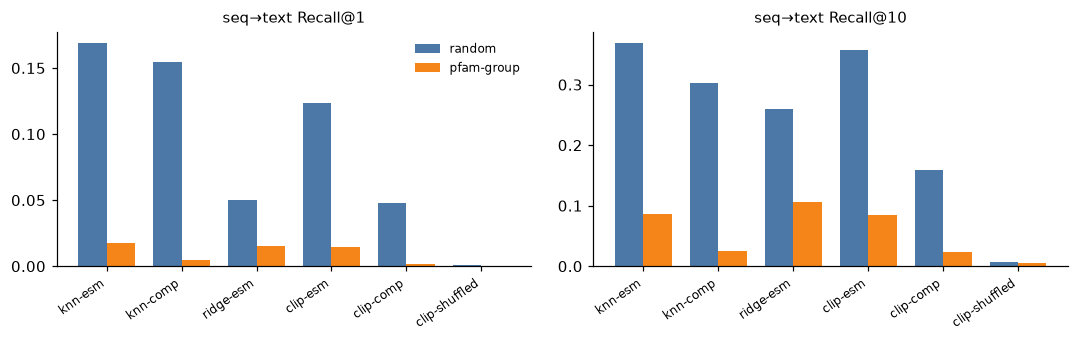

In [11]:
def paired_diff(sp, m1, m2, k=1, direction="s2t"):
    h1 = (RK[(sp, m1, direction)] < k).astype(float)
    h2 = (RK[(sp, m2, direction)] < k).astype(float)
    bs = (BW @ (h1 - h2)) / BW.sum(1)
    return f"{(h1 - h2).mean():+.3f} [{np.percentile(bs, 2.5):+.3f}, {np.percentile(bs, 97.5):+.3f}]"


print("주 비교(사전 지정): seq→text Recall@1")
for sp in FOLDS:
    print(f"  {sp:10s} CLIP head − 최근접 전이: {paired_diff(sp, 'clip-esm', 'knn-esm')} | CLIP − 선형 사상: {paired_diff(sp, 'clip-esm', 'ridge-esm')} | CLIP(ESM) − CLIP(조성): {paired_diff(sp, 'clip-esm', 'clip-comp')}")
drop = {m: (RK[("random", m, 's2t')] < 1).mean() - (RK[("pfam-group", m, 's2t')] < 1).mean() for m in METHODS}
print("random → Pfam 묶음 Recall@1 하락폭:", {m: round(v, 3) for m, v in drop.items()})
fig, axs = plt.subplots(1, 2, figsize=(10, 3.2))
for ax, k in zip(axs, (1, 10)):
    for j, (sp, c) in enumerate(zip(FOLDS, ["#4c78a8", "#f58518"])):
        vals = [(RK[(sp, m, "s2t")] < k).mean() for m in METHODS]
        ax.bar(np.arange(len(METHODS)) + (j - 0.5) * 0.38, vals, 0.38, color=c, label=sp)
    ax.set_xticks(np.arange(len(METHODS)))
    ax.set_xticklabels(METHODS, rotation=35, ha="right", fontsize=8)
    ax.set_title(f"seq→text Recall@{k}", fontsize=10)
axs[0].legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

## 6. 진단: 성능은 어디서 오는가
(a) **텍스트 근접 중복**으로 층화: test 텍스트가 train에 거의 같은 문장(코사인 ≥ 0.9)을 가진 질의와 그렇지 않은 질의의 Recall@1. (b) **모달리티 간극(modality gap)**: 정렬 후에도 두 모달리티의 점이 서로 다른 영역(원뿔)에 모이는 현상(Liang et al. 2022) — 폴드 0의 test 임베딩으로 학습 전후 비교. (c) 틀린 예: 폴드 0, Pfam 묶음 분할에서 seq→text 상위 후보.

In [12]:
rows = []
for sp in FOLDS:
    near = ND[sp] >= 0.9
    for m in ["knn-esm", "ridge-esm", "clip-esm", "clip-comp"]:
        r = RK[(sp, m, "s2t")]
        rows.append({"분할": sp, "방법": m, "n(근접중복 있음)": int(near.sum()), "n(없음)": int((~near).sum()),
                     "R@1 있음": (r[near] < 1).mean(), "R@1 없음": (r[~near] < 1).mean(), "R@10 있음": (r[near] < 10).mean(), "R@10 없음": (r[~near] < 10).mean()})
print(pd.DataFrame(rows).round(3).to_string(index=False))

        분할        방법  n(근접중복 있음)  n(없음)  R@1 있음  R@1 없음  R@10 있음  R@10 없음
    random   knn-esm        2438   4959   0.245   0.131    0.501    0.304
    random ridge-esm        2438   4959   0.078   0.036    0.368    0.206
    random  clip-esm        2438   4959   0.214   0.079    0.532    0.271
    random clip-comp        2438   4959   0.110   0.017    0.314    0.083
pfam-group   knn-esm        1226   6171   0.030   0.015    0.122    0.080
pfam-group ridge-esm        1226   6171   0.022   0.014    0.174    0.093
pfam-group  clip-esm        1226   6171   0.031   0.011    0.146    0.073
pfam-group clip-comp        1226   6171   0.002   0.002    0.043    0.020


In [13]:
tr, te = FOLDS["pfam-group"][0]
Xtr, Xte = zscore(E[tr], E[te])
hs, ht, ls, losses = train_clip(Xtr, T[tr])
with torch.no_grad():
    a, b = hs(torch.tensor(Xte)).numpy(), ht(torch.tensor(T[te])).numpy()
    hs0, ht0 = Head(480), Head(384)
    a0, b0 = hs0(torch.tensor(Xte)).numpy(), ht0(torch.tensor(T[te])).numpy()


# 주의: 학습 전(무작위 head) 수치는 입력 스케일 차이(서열은 z-score, 텍스트는 L2 정규화된 384차원)의 산물이라 '학습이 줄인 간극'으로 읽으면 안 된다
def gap_stats(a, b):
    S = a @ b.T
    return dict(중심간_거리=np.linalg.norm(a.mean(0) - b.mean(0)), 서열_퍼짐=np.linalg.norm(a - a.mean(0), axis=1).mean(), 텍스트_퍼짐=np.linalg.norm(b - b.mean(0), axis=1).mean(),
                짝_코사인=np.diag(S).mean(), 비짝_코사인=(S.sum() - np.trace(S)) / (S.size - len(S)))


print(pd.DataFrame({"학습 전(무작위 head)": gap_stats(a0, b0), "학습 후(40 에폭)": gap_stats(a, b)}).round(3).to_string())
print("학습된 온도 τ = %.3f | 학습 손실 첫/마지막 에폭: %.3f → %.3f" % (1 / ls.exp().item(), losses[0], losses[-1]))

        학습 전(무작위 head)  학습 후(40 에폭)
중심간_거리           1.030        0.203
서열_퍼짐            0.901        0.988
텍스트_퍼짐           0.257        0.982
짝_코사인            0.029        0.134
비짝_코사인           0.030        0.008
학습된 온도 τ = 0.042 | 학습 손실 첫/마지막 에폭: 4.652 → 0.364


In [14]:
S = a @ b.T
order_ = np.argsort(ranks_of(S))
for i in [order_[int(q * len(S))] for q in (0.05, 0.5, 0.9)]:                  # 쉬운 질의 / 중간 / 어려운 질의
    top = np.argsort(-S[i])[:3]
    print(f"[질의 {df.acc.iloc[te[i]]} {df.gene.iloc[te[i]]}] 정답 순위 {ranks_of(S)[i] + 1}/{len(S)}")
    print("   정답  :", df.text.iloc[te[i]][:110])
    for j in top:
        print("   후보  :", df.text.iloc[te[j]][:110], "(%s)" % df.gene.iloc[te[j]])

[질의 Q9UBQ6 EXTL2] 정답 순위 5/1480
   정답  : Glycosyltransferase required for the biosynthesis of heparan-sulfate and responsible for the alternating addit
   후보  : Reducing-end exoglycosidase involved in glycan degradation. Hydrolyzes N,N'-diacetylchitobiose (GlnNAc2) and h (CTBS)
   후보  : Repair polymerase that plays a key role in base-excision repair. During this process, the damaged base is exci (POLB)
   후보  : Alpha-1,3-xylosyltransferase, which elongates the O-linked xylose-glucose disaccharide attached to EGF-like re (XXYLT1)
[질의 Q9UMQ3 BARX2] 정답 순위 232/1480
   정답  : Transcription factor. Binds optimally to the DNA consensus sequence 5'-YYTAATGRTTTTY-3'. May control the expre
   후보  : Transcription factor that acts as activator.. (ARGFX)
   후보  : Recruited by SOX15 to FOXK1 promoters where it acts as a transcriptional coactivator of FOXK1.. (FHL3)
   후보  : Shows weak transcriptional activator activity.. (POU5F1B)
[질의 Q8NFH3 NUP43] 정답 순위 1054/1480
   정답  : Component of the Nup107-160 

## 7. 민감도: 사전에 고정한 설정이 결과를 좌우하는가
폴드 5개를 모두 써서 **Pfam 묶음 분할**의 seq→text Recall@1/10만 본다. 설정을 이 표로 고르지 않았다 — 결론이 설정에 의존하는지 확인하는 용도다.

In [15]:
configs = {"기본(τ0=0.07, 40ep)": {}, "τ0=0.03": dict(tau0=0.03), "τ0=0.2": dict(tau0=0.2), "10 에폭": dict(epochs=10), "100 에폭": dict(epochs=100), "온도 고정(학습 안 함)": dict(learn_tau=False)}
rows = []
t0 = time.time()
for name, kw in configs.items():
    rk = np.zeros(N, int)
    for tr, te in FOLDS["pfam-group"]:
        Xtr, Xte = zscore(E[tr], E[te])
        hs, ht, _, _ = train_clip(Xtr, T[tr], **kw)
        rk[te] = ranks_of(heads_scores(hs, ht, Xte, T[te]))
    rows.append({"설정": name, "R@1": (rk < 1).mean(), "R@10": (rk < 10).mean(), "중앙 순위": np.median(rk / (GAL["pfam-group"] - 1))})
print(pd.DataFrame(rows).round(3).to_string(index=False))
print("민감도 계산: %.0f초 | 참고 최근접 전이 R@1 %.3f" % (time.time() - t0, (RK[("pfam-group", "knn-esm", "s2t")] < 1).mean()))

               설정   R@1  R@10  중앙 순위
기본(τ0=0.07, 40ep) 0.015 0.085  0.173
          τ0=0.03 0.015 0.087  0.162
           τ0=0.2 0.014 0.074  0.199
            10 에폭 0.016 0.107  0.120
           100 에폭 0.012 0.074  0.185
    온도 고정(학습 안 함) 0.016 0.088  0.187
민감도 계산: 159초 | 참고 최근접 전이 R@1 0.018


## 정리
(실행 결과를 확인한 뒤 README의 결과 요약에서 수치와 함께 해석한다. 이 노트북은 동결 인코더 + 작은 head, 사람 단백질 7,397개와 UniProt 큐레이션 텍스트, 시드 0의 5-fold에 대한 결과이며 ProtST·ProTrek 같은 대규모 모델의 성능을 대표하지 않는다.)